# AI or Human? Detecting AI-Generated Essays with Machine Learning
**Mini Project, Programming for Data Science (Master)**
Student: **Seyran Gurbanov**, Riga Nordic University

This notebook contains the full data science work of the project:

1. Loading the data
2. Data understanding
3. Data cleaning
4. Feature engineering (writing-style features)
5. Exploratory Data Analysis (EDA)
6. Model training and comparison
7. Evaluation of the best model (Accuracy, Precision, Recall, F1, ROC, cross-validation)
8. Explainability (which words point to AI or human)
9. Error analysis and robustness to short texts
10. External validation on a different type of text
11. Saving the model for the web app

The trained model is used in the online web app (Streamlit).

## 0. Setup
When the notebook runs in Google Colab, it first downloads the project from GitHub, so the data and the helper code are available.

In [1]:
import os, sys, json, time, subprocess

REPO_URL = "https://github.com/seiranabdullah/ai-or-human-detector.git"

if "google.colab" in sys.modules and not os.path.exists("ai-or-human-detector"):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
if os.path.exists("ai-or-human-detector"):
    os.chdir("ai-or-human-detector")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working folder:", os.getcwd())

Working folder: /home/claude/aiorhuman


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

try:
    from text_features import features_frame, text_features, FEATURE_NAMES
except ImportError:
    from src.text_features import features_frame, text_features, FEATURE_NAMES

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
HUMAN_COLOR, AI_COLOR = "#2E86AB", "#E4572E"
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("model", exist_ok=True)
RANDOM_STATE = 42


def save_fig(name):
    """Save the current chart for the report and the presentation."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 1. Loading the data
**Dataset:** *LLM - Detect AI Generated Text Dataset* (Kaggle, author: Sunil Thite).
It contains student essays written by humans and essays generated by Large Language Models (LLMs).

| Column | Meaning |
|---|---|
| `text` | the full essay |
| `generated` | label: **0 = human**, **1 = AI-generated** |

In [3]:
df_raw = pd.read_csv("data/essays.csv.gz")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (29145, 2)


text  generated
0  Car-free cities have become a subject of increasing interest and debate in recent years, as urban areas around the w...          1
1  Car Free Cities  Car-free cities, a concept gaining traction in contemporary urban planning, seek to transform the w...          1
2    A Sustainable Urban Future  Car-free cities are emerging as a powerful response to the pressing challenges of urba...          1
3    Pioneering Sustainable Urban Living  In an era marked by rapid urbanization, car-free cities have emerged as a vis...          1
4    The Path to Sustainable Urban Living  In an age of rapid urbanization, the concept of car-free cities is gaining m...          1

## 2. Data understanding

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 29145 entries, 0 to 29144
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       29145 non-null  str  
 1   generated  29145 non-null  int64
dtypes: int64(1), str(1)
memory usage: 455.5 KB


In [5]:
summary = pd.DataFrame({
    "rows": [len(df_raw)],
    "missing values": [int(df_raw.isna().sum().sum())],
    "duplicate texts": [int(df_raw["text"].duplicated().sum())],
    "human essays (0)": [int((df_raw["generated"] == 0).sum())],
    "AI essays (1)": [int((df_raw["generated"] == 1).sum())],
})
summary

,rows,missing values,duplicate texts,human essays (0),AI essays (1)
0,29145,0,1805,17508,11637


In [6]:
word_count_raw = df_raw["text"].str.split().str.len()
print("Shortest text (words):", word_count_raw.min())
print("Longest text (words): ", word_count_raw.max())
print("Texts with fewer than 50 words:", int((word_count_raw < 50).sum()))
print()
print("Example of a very short 'essay':", repr(df_raw.loc[word_count_raw.idxmin(), "text"][:200]))

Shortest text (words): 1
Longest text (words):  1650
Texts with fewer than 50 words: 7

Example of a very short 'essay': ']'


**Findings:**

- There are **no missing values**.
- There are **duplicate essays**. They would leak from the training set into the test set and make the results look better than they are.
- Some AI "essays" are only one or a few words long (broken generations). They are noise.
- The classes are **not balanced**: there are more human essays than AI essays.

## 3. Data cleaning
Cleaning steps:

1. Strip extra spaces at the start and end of each text.
2. Remove duplicate texts (`drop_duplicates`).
3. Remove texts with fewer than 50 words (too short to be an essay).
4. Check missing values again (`dropna`).

In [7]:
df = df_raw.copy()
df["text"] = df["text"].str.strip()
before = len(df)
df = df.drop_duplicates(subset="text")
after_dupes = len(df)
df = df[df["text"].str.split().str.len() >= 50]
after_short = len(df)
df = df.dropna().reset_index(drop=True)

cleaning_log = pd.DataFrame({
    "step": ["original data", "remove duplicates", "remove texts < 50 words", "final clean data"],
    "rows": [before, after_dupes, after_short, len(df)],
})
cleaning_log["removed"] = (-cleaning_log["rows"].diff()).fillna(0).astype(int)
cleaning_log.loc[3, "removed"] = before - len(df)
cleaning_log

,step,rows,removed
0,original data,29145,0
1,remove duplicates,27302,1843
2,remove texts < 50 words,27296,6
3,final clean data,27296,1849


In [8]:
print(df["generated"].value_counts().rename({0: "human", 1: "AI"}))
print()
print((df["generated"].value_counts(normalize=True) * 100).round(1).rename({0: "human %", 1: "AI %"}))

generated
human    16116
AI       11180
Name: count, dtype: int64

generated
human %    59.0
AI %       41.0
Name: proportion, dtype: float64


## 4. Feature engineering: writing-style features
Besides the words themselves, we measure **how** a text is written:

| Feature | Meaning |
|---|---|
| word_count | number of words |
| avg_word_length | average number of letters per word |
| sentence_count | number of sentences |
| avg_sentence_length | average words per sentence |
| sentence_length_std | how much sentence length changes (*burstiness*) |
| type_token_ratio | unique words / all words (vocabulary richness) |
| punctuation_per_100_words | punctuation marks per 100 words |
| paragraph_count | number of paragraphs |

In [9]:
t0 = time.time()
style = features_frame(df["text"])
style["label"] = df["generated"].map({0: "Human", 1: "AI"})
print(f"Features calculated in {time.time() - t0:.1f} s")
style.head()

Features calculated in 9.9 s


,word_count,avg_word_length,sentence_count,avg_sentence_length,sentence_length_std,type_token_ratio,punctuation_per_100_words,paragraph_count,label
0,597,5.710218,28,21.321429,6.557730,0.452261,10.217755,1,AI
1,532,5.892857,26,20.461538,6.505801,0.501880,13.157895,1,AI
2,531,6.041431,27,19.666667,7.039571,0.480226,12.241055,1,AI
3,538,5.802974,23,23.391304,10.428803,0.485130,11.152416,1,AI
4,531,5.811676,22,24.136364,10.720819,0.470810,12.052731,1,AI


## 5. Exploratory Data Analysis (EDA)
### 5.1 Class balance

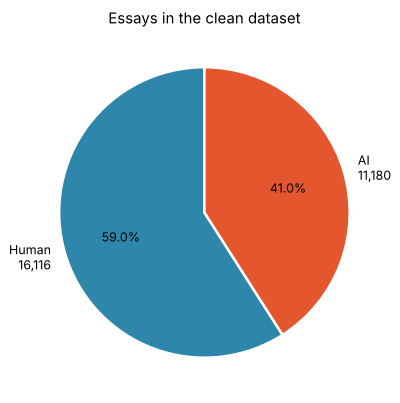

In [10]:
counts = style["label"].value_counts()
plt.figure(figsize=(4.6, 4.6))
plt.pie(counts.values, labels=[f"{k}\n{v:,}" for k, v in counts.items()], autopct="%1.1f%%",
        colors=[HUMAN_COLOR if k == "Human" else AI_COLOR for k in counts.index],
        startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
plt.title("Essays in the clean dataset")
save_fig("01_class_balance")

### 5.2 Descriptive statistics by class

In [11]:
style.groupby("label")[FEATURE_NAMES].mean().T.round(2)

label,AI,Human
word_count,308.00,418.19
avg_word_length,5.11,4.44
sentence_count,14.28,21.49
avg_sentence_length,22.53,21.90
sentence_length_std,8.28,10.21
type_token_ratio,0.55,0.44
punctuation_per_100_words,6.03,5.00
paragraph_count,3.94,5.11


In [12]:
stats = pd.DataFrame({
    "mean": style.groupby("label")["word_count"].mean(),
    "median": style.groupby("label")["word_count"].median(),
    "std": style.groupby("label")["word_count"].std(),
    "skewness": style.groupby("label")["word_count"].skew(),
    "kurtosis": style.groupby("label")["word_count"].apply(lambda s: s.kurt()),
}).round(2)
stats

,mean,median,std,skewness,kurtosis
label,,,,,
AI,308.00,320.0,122.27,0.61,0.71
Human,418.19,391.0,180.95,1.13,2.01


### 5.3 Length distribution (histogram)

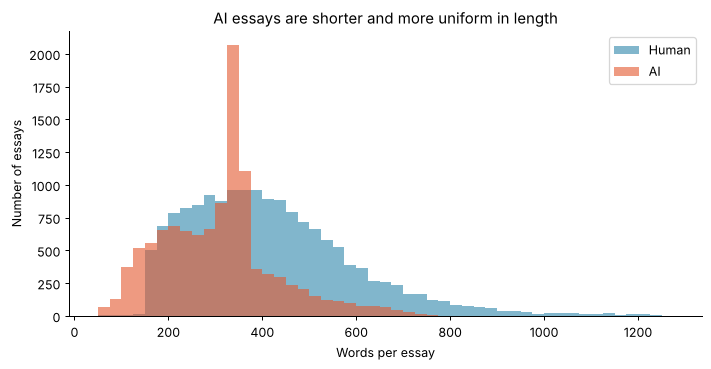

In [13]:
plt.figure(figsize=(8, 4.2))
bins = np.arange(50, 1300, 25)
for label, color in [("Human", HUMAN_COLOR), ("AI", AI_COLOR)]:
    plt.hist(style.loc[style["label"] == label, "word_count"], bins=bins, alpha=0.6, color=color, label=label)
plt.xlabel("Words per essay")
plt.ylabel("Number of essays")
plt.title("AI essays are shorter and more uniform in length")
plt.legend()
save_fig("02_length_histogram")

### 5.4 Writing style by class (boxplots)

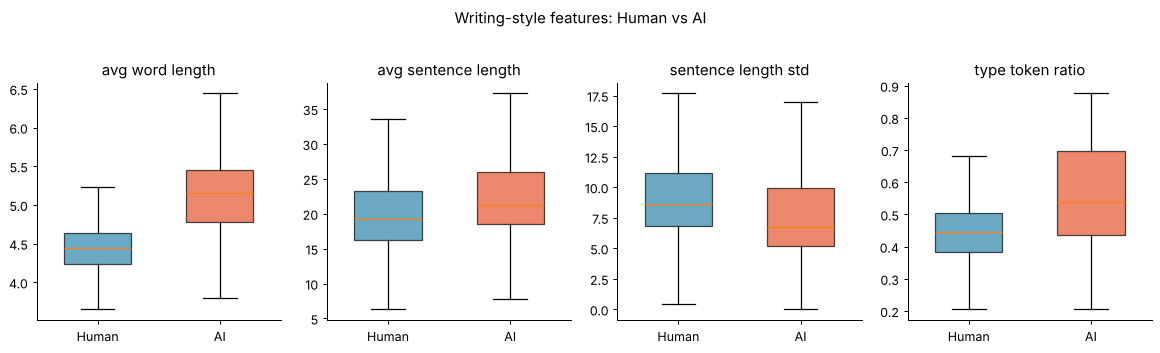

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, col in zip(axes, ["avg_word_length", "avg_sentence_length", "sentence_length_std", "type_token_ratio"]):
    data = [style.loc[style["label"] == k, col] for k in ["Human", "AI"]]
    box = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55)
    ax.set_xticks([1, 2], ["Human", "AI"])
    for patch, color in zip(box["boxes"], [HUMAN_COLOR, AI_COLOR]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(col.replace("_", " "))
plt.suptitle("Writing-style features: Human vs AI", y=1.02)
save_fig("03_style_boxplots")

### 5.5 Correlation between features

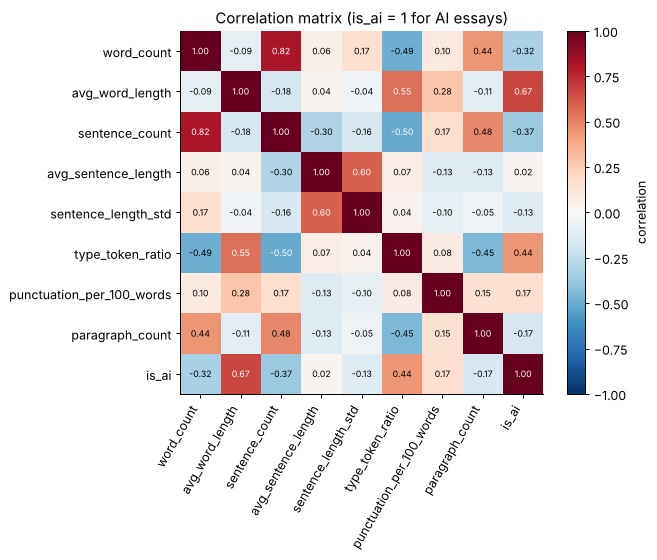

In [15]:
corr = style[FEATURE_NAMES].assign(is_ai=(style["label"] == "AI").astype(int)).corr()
plt.figure(figsize=(7.5, 6.2))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                 color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
plt.title("Correlation matrix (is_ai = 1 for AI essays)")
save_fig("04_correlation")

In [16]:
corr["is_ai"].drop("is_ai").sort_values().round(3)

sentence_count              -0.369
word_count                  -0.322
paragraph_count             -0.171
sentence_length_std         -0.131
avg_sentence_length          0.024
punctuation_per_100_words    0.172
type_token_ratio             0.438
avg_word_length              0.665
Name: is_ai, dtype: float64

### 5.6 Scatter plot: length vs vocabulary richness

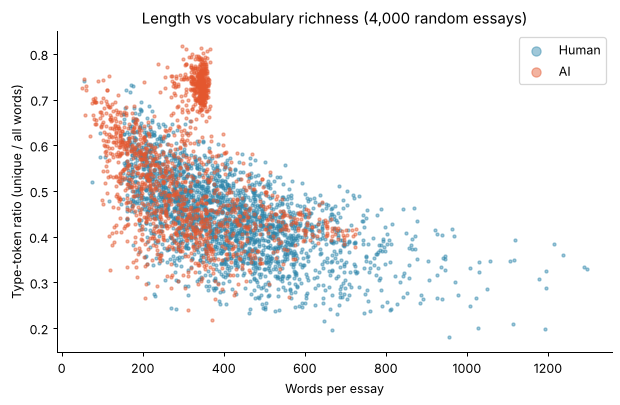

In [17]:
sample = style.sample(4000, random_state=RANDOM_STATE)
plt.figure(figsize=(7, 4.6))
for label, color in [("Human", HUMAN_COLOR), ("AI", AI_COLOR)]:
    part = sample[sample["label"] == label]
    plt.scatter(part["word_count"], part["type_token_ratio"], s=6, alpha=0.45, color=color, label=label)
plt.xlabel("Words per essay")
plt.ylabel("Type-token ratio (unique / all words)")
plt.title("Length vs vocabulary richness (4,000 random essays)")
plt.legend(markerscale=3)
save_fig("05_scatter_length_ttr")

### 5.7 Most frequent words in each class (bag of words)

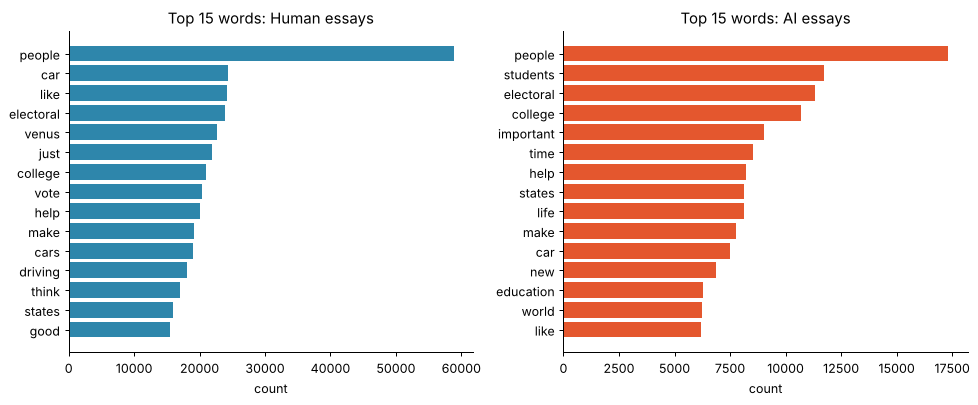

In [18]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english", min_df=5)
    counts = cv.fit_transform(texts)
    freq = np.asarray(counts.sum(axis=0)).ravel()
    order = freq.argsort()[::-1][:n]
    return pd.Series(freq[order], index=cv.get_feature_names_out()[order])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (label, value, color) in zip(axes, [("Human", 0, HUMAN_COLOR), ("AI", 1, AI_COLOR)]):
    tw = top_words(df.loc[df["generated"] == value, "text"])
    ax.barh(tw.index[::-1], tw.values[::-1], color=color)
    ax.set_title(f"Top 15 words: {label} essays")
    ax.set_xlabel("count")
save_fig("06_top_words")

**EDA conclusions:**

- AI essays are **shorter** and their length is **more uniform** (smaller standard deviation).
- AI essays use **longer words** and have **less variation in sentence length** (lower burstiness).
- Both classes share many essay topics (e.g. car-free cities, online learning), but some topics such as *Venus*, *the Face on Mars (NASA)* and *driverless cars* appear much more often in human essays. This is a **dataset bias**: the model may partly learn topics instead of style (see Section 8).

## 6. Model training and comparison
The data is split into **80% training** and **20% testing** (stratified, so both parts keep the same class ratio).

We compare four models:

| # | Model | Input |
|---|---|---|
| 1 | Random Forest | 8 writing-style features only |
| 2 | Multinomial Naive Bayes | word counts (CountVectorizer) |
| 3 | Logistic Regression | TF-IDF of words and word pairs |
| 4 | Linear SVM | TF-IDF of words and word pairs |

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["generated"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["generated"])
print("Training essays:", len(X_train), "  Test essays:", len(X_test))

Training essays: 21836   Test essays: 5460


In [20]:
models = {
    "Random Forest (style features)": make_pipeline(
        StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    "Naive Bayes (word counts)": make_pipeline(
        CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000), MultinomialNB()),
    "Logistic Regression (TF-IDF)": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000, sublinear_tf=True),
        LogisticRegression(max_iter=2000, C=5)),
    "Linear SVM (TF-IDF)": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000, sublinear_tf=True),
        LinearSVC(C=0.5)),
}

style_train = features_frame(X_train)
style_test = features_frame(X_test)

results, fitted = [], {}
for name, model in models.items():
    use_style = name.startswith("Random Forest")
    xtr, xte = (style_train, style_test) if use_style else (X_train, X_test)
    t0 = time.time()
    model.fit(xtr, y_train)
    train_time = time.time() - t0
    pred = model.predict(xte)
    fitted[name] = model
    results.append({
        "model": name,
        "accuracy": metrics.accuracy_score(y_test, pred),
        "precision": metrics.precision_score(y_test, pred),
        "recall": metrics.recall_score(y_test, pred),
        "f1": metrics.f1_score(y_test, pred),
        "train_time_s": train_time,
    })
    print(f"{name:34s} F1 = {results[-1]['f1']:.4f}   ({train_time:.1f} s)")

results_df = pd.DataFrame(results).set_index("model").round(4)
results_df

Random Forest (style features)     F1 = 0.9174   (3.2 s)
Naive Bayes (word counts)          F1 = 0.9770   (20.7 s)
Logistic Regression (TF-IDF)       F1 = 0.9912   (22.1 s)
Linear SVM (TF-IDF)                F1 = 0.9955   (22.2 s)


,accuracy,precision,recall,f1,train_time_s
model,,,,,
Random Forest (style features),0.9333,0.9309,0.9043,0.9174,3.1515
Naive Bayes (word counts),0.9815,0.9949,0.9597,0.9770,20.7165
Logistic Regression (TF-IDF),0.9929,0.9973,0.9852,0.9912,22.0729
Linear SVM (TF-IDF),0.9963,0.9995,0.9915,0.9955,22.2127


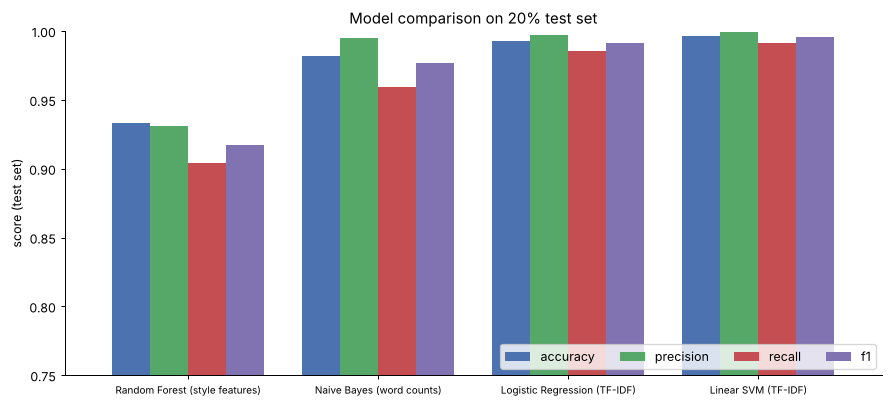

In [21]:
ax = results_df[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", figsize=(10, 4.6), width=0.8,
                                                                color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.set_ylim(0.75, 1.0)
ax.set_ylabel("score (test set)")
ax.set_xlabel("")
ax.set_title("Model comparison on 20% test set")
plt.xticks(rotation=0, fontsize=8)
plt.legend(loc="lower right", ncol=4)
save_fig("07_model_comparison")

**Model choice:** the text-based models are far better than the model with only 8 style features.
**Logistic Regression with TF-IDF** is chosen for the web app. Its scores are at the top together with the SVM, it gives a real **probability** (e.g. "92% AI"), and its weights are easy to explain word by word.

## 7. Evaluation of the best model

In [22]:
best_name = "Logistic Regression (TF-IDF)"
best = fitted[best_name]
y_pred = best.predict(X_test)
y_prob = best.predict_proba(X_test)[:, 1]
print(metrics.classification_report(y_test, y_pred, target_names=["Human", "AI"], digits=4))

              precision    recall  f1-score   support

       Human     0.9898    0.9981    0.9940      3224
          AI     0.9973    0.9852    0.9912      2236

    accuracy                         0.9929      5460
   macro avg     0.9936    0.9917    0.9926      5460
weighted avg     0.9929    0.9929    0.9929      5460



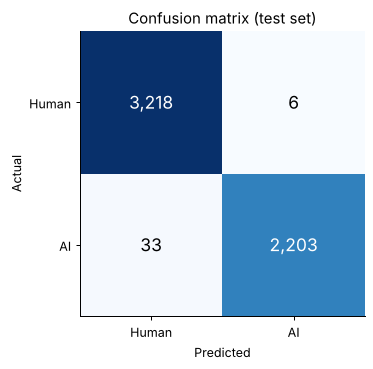

In [23]:
cm = metrics.confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.6, 4.2))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=14,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks([0, 1], ["Human", "AI"])
plt.yticks([0, 1], ["Human", "AI"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (test set)")
save_fig("08_confusion_matrix")

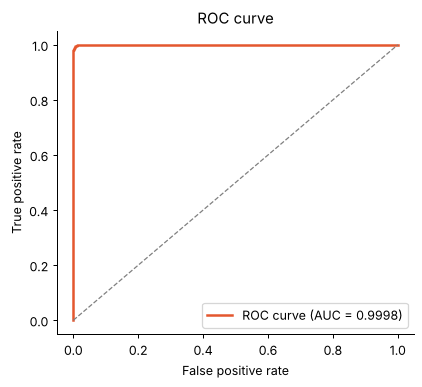

In [24]:
fpr, tpr, _ = metrics.roc_curve(y_test, y_prob)
auc = metrics.roc_auc_score(y_test, y_prob)
plt.figure(figsize=(4.8, 4.4))
plt.plot(fpr, tpr, color=AI_COLOR, lw=2, label=f"ROC curve (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="grey", lw=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend(loc="lower right")
save_fig("09_roc_curve")

### 5-fold cross-validation
To be sure the result does not depend on one lucky split, the model is trained and tested 5 times on different parts of the data (all CPU cores are used with `n_jobs=-1`).

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
t0 = time.time()
cv_f1 = cross_val_score(models[best_name], df["text"], df["generated"], cv=cv, scoring="f1", n_jobs=-1)
print("F1 per fold:", np.round(cv_f1, 4))
print(f"Mean F1 = {cv_f1.mean():.4f}  (std = {cv_f1.std():.4f})   time: {time.time() - t0:.0f} s")

F1 per fold: [0.996  0.9939 0.9939 0.9919 0.9919]
Mean F1 = 0.9935  (std = 0.0015)   time: 78 s


## 8. Explainability: which words point to AI or human?
In Logistic Regression every word (or word pair) has a weight. A **positive** weight pushes the text towards **AI**, a **negative** weight pushes it towards **human**.

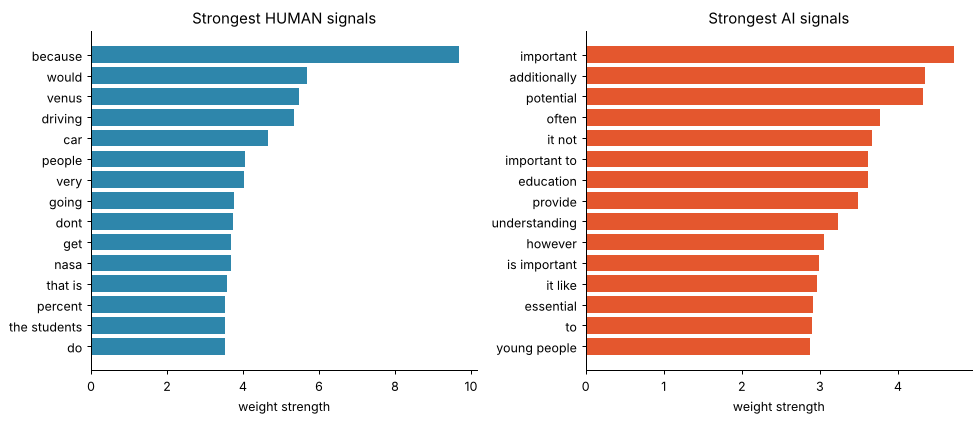

In [26]:
vectorizer = best.named_steps["tfidfvectorizer"]
classifier = best.named_steps["logisticregression"]
weights = pd.Series(classifier.coef_[0], index=vectorizer.get_feature_names_out())
top_ai = weights.sort_values(ascending=False).head(15)
top_human = weights.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].barh(top_human.index[::-1], -top_human.values[::-1], color=HUMAN_COLOR)
axes[0].set_title("Strongest HUMAN signals")
axes[1].barh(top_ai.index[::-1], top_ai.values[::-1], color=AI_COLOR)
axes[1].set_title("Strongest AI signals")
for ax in axes:
    ax.set_xlabel("weight strength")
save_fig("10_explainability_words")

**Interpretation:**

- **AI signals** are formal linking words and "safe" academic phrases: *additionally*, *potential*, *essential*, *it is important*, *however*. This matches what teachers often notice in AI texts.
- **Human signals** are simple, informal words (*because*, *very*, *going*, *get*, *dont* without an apostrophe), but also **topic words** (*venus*, *nasa*, *car*, *driving*).
- The topic words confirm the **dataset bias** found in the EDA: some essay prompts were written mostly by humans. This is an honest limitation and a reason to train on more balanced data in the future.

## 9. Error analysis and robustness
### 9.1 Examples of wrong predictions

In [27]:
errors = pd.DataFrame({"text": X_test, "actual": y_test, "predicted": y_pred, "p_ai": y_prob})
errors = errors[errors["actual"] != errors["predicted"]]
print("Wrong predictions:", len(errors), "of", len(y_test))
errors.assign(text=errors["text"].str[:160]).head(6)

Wrong predictions: 39 of 5460


,text,actual,predicted,p_ai
22018,"There are a lot of reasons why people today do not give enough time to helping their communities. Some people believe that it is not their responsibility, becau",1,0,0.369218
23270,"In every field, school, work, social etc. There will be people who are better than you at one thing and worse at another. If you want to be the best at somethin",1,0,0.477134
24182,"It is natural that people try to perform better than others at everything they do. However, it is also natural for people to try not to do as well as others. Fo",1,0,0.252158
14713,"Hi, my name is Jill and I'm a scientist at NASA. I'm here to tell you that the Face on Mars is not created by aliens, it's just a natural landform. Some people",1,0,0.341650
14856,"Intro:\nThe authur of ""The Challenge of Exploring Venus"" thinks that studying Venus is a good idea even though it's a dangerous place. They give lots of reasons",1,0,0.195526
14827,The Facial Action Coding System is like totally awesome! It can detect like every single emotion that a person is feeling just by looking at their face! It's li,1,0,0.482154


### 9.2 How much text does the model need?
We cut every test essay to its first N words and measure the F1-score again.

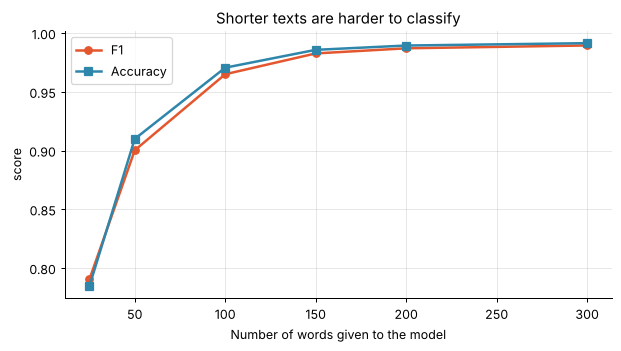

,words,accuracy,f1
0,25,0.7848,0.7905
1,50,0.9099,0.9002
2,100,0.9705,0.9649
3,150,0.9857,0.9827
4,200,0.9894,0.9870
5,300,0.9914,0.9894


In [28]:
lengths = [25, 50, 100, 150, 200, 300]
robust = []
for n in lengths:
    short = X_test.apply(lambda t: " ".join(t.split()[:n]))
    pred_n = best.predict(short)
    robust.append({"words": n, "accuracy": metrics.accuracy_score(y_test, pred_n),
                   "f1": metrics.f1_score(y_test, pred_n)})
robust_df = pd.DataFrame(robust)

plt.figure(figsize=(7, 4))
plt.plot(robust_df["words"], robust_df["f1"], marker="o", color=AI_COLOR, lw=2, label="F1")
plt.plot(robust_df["words"], robust_df["accuracy"], marker="s", color=HUMAN_COLOR, lw=2, label="Accuracy")
plt.xlabel("Number of words given to the model")
plt.ylabel("score")
plt.title("Shorter texts are harder to classify")
plt.legend()
plt.grid(alpha=0.3)
save_fig("11_robustness_length")
robust_df.round(4)

## 10. External validation: does it work on a different type of text?
A good research test is to try the model on texts it has **never seen in style or topic**.
We use 2,000 scientific abstracts about COVID-19 (1,000 human, 1,000 GPT-3) from the **AI-GA dataset** (Theocharopoulos et al., 2023).

In [29]:
external = pd.read_csv("data/external_abstracts_sample.csv")
ext_pred = best.predict(external["text"])
ext_report = {
    "accuracy": metrics.accuracy_score(external["generated"], ext_pred),
    "precision": metrics.precision_score(external["generated"], ext_pred, zero_division=0),
    "recall": metrics.recall_score(external["generated"], ext_pred),
    "f1": metrics.f1_score(external["generated"], ext_pred),
    "predicted_as_ai_%": 100 * ext_pred.mean(),
}
pd.Series(ext_report).round(4)

accuracy              0.5005
precision             0.5003
recall                1.0000
f1                    0.6669
predicted_as_ai_%    99.9500
dtype: float64

**Important finding (domain shift):** on scientific abstracts the model labels almost **every** text as AI, even the human ones.
Formal scientific language looks like "AI style" to a model that learned from student essays.

This shows the main **limitation** of AI detectors: they work well only on the **same type of text** they were trained on.
In the web app this is shown as a clear warning: *"Best for English student essays of 150+ words. The result is a probability, not proof."*

## 11. Save the model for the web app

In [30]:
final_model = models[best_name]
t0 = time.time()
final_model.fit(df["text"], df["generated"])
print(f"Final model trained on all {len(df):,} clean essays in {time.time() - t0:.0f} s")
joblib.dump(final_model, "model/ai_detector.joblib", compress=3)
print("Model size:", round(os.path.getsize("model/ai_detector.joblib") / 1e6, 2), "MB")

app_stats = {
    "dataset": {
        "name": "LLM - Detect AI Generated Text Dataset (Kaggle)",
        "rows_original": int(before),
        "rows_clean": int(len(df)),
        "human": int((df["generated"] == 0).sum()),
        "ai": int((df["generated"] == 1).sum()),
        "duplicates_removed": int(before - after_dupes),
        "short_removed": int(after_dupes - after_short),
    },
    "style_means": style.groupby("label")[FEATURE_NAMES].mean().round(3).to_dict(),
    "word_count_hist": {
        label: np.histogram(style.loc[style["label"] == label, "word_count"], bins=bins)[0].tolist()
        for label in ["Human", "AI"]
    },
    "word_count_bins": bins[:-1].tolist(),
    "model_comparison": results_df.reset_index().to_dict(orient="records"),
    "best_model": best_name,
    "test_metrics": {
        "accuracy": float(metrics.accuracy_score(y_test, y_pred)),
        "precision": float(metrics.precision_score(y_test, y_pred)),
        "recall": float(metrics.recall_score(y_test, y_pred)),
        "f1": float(metrics.f1_score(y_test, y_pred)),
        "roc_auc": float(auc),
        "confusion_matrix": cm.tolist(),
    },
    "cross_validation_f1": [float(x) for x in cv_f1],
    "robustness": robust_df.round(4).to_dict(orient="records"),
    "external_validation": {k: float(v) for k, v in ext_report.items()},
    "top_ai_words": top_ai.round(3).to_dict(),
    "top_human_words": top_human.round(3).to_dict(),
}
with open("model/model_stats.json", "w") as f:
    json.dump(app_stats, f, indent=2)
print("Saved model/ai_detector.joblib and model/model_stats.json")

Final model trained on all 27,296 clean essays in 26 s
Model size: 0.99 MB
Saved model/ai_detector.joblib and model/model_stats.json


## 12. Quick test of the saved model

In [31]:
loaded = joblib.load("model/ai_detector.joblib")
examples = [
    "In today's rapidly evolving world, technology plays a crucial role in shaping education. "
    "Furthermore, it is essential to consider the various benefits and drawbacks of online learning. "
    "In conclusion, a balanced approach ensures that students can thrive in a digital environment.",
    "honestly i dont think cars should be banned in cities. my dad drives me to school every day and "
    "the bus near our house comes like once an hour so what are we supposed to do?? i get that pollution "
    "is bad but people need to get to work.",
]
for text in examples:
    print(f"{loaded.predict_proba([text])[0, 1] * 100:5.1f}% AI  <-  {text[:70]}...")

 99.9% AI  <-  In today's rapidly evolving world, technology plays a crucial role in ...
  6.6% AI  <-  honestly i dont think cars should be banned in cities. my dad drives m...


## Conclusion
- After cleaning, the dataset contains about 27,000 essays.
- EDA shows clear style differences: AI essays are shorter, more uniform, use longer words and vary sentence length less.
- TF-IDF + Logistic Regression reaches an F1-score above 0.99 on the test set and in 5-fold cross-validation.
- The model needs enough text: below about 100 words the quality drops.
- **Main limitation:** on a different type of text (scientific abstracts) the model fails. AI detection should be used as **support for a human decision, never as proof**.